 **Implementación del Método de Newton**

 **LOPEZ MARTINEZ JOSELIN GUADALUPE**

## 1. Formulación del Problema y del Método

El *Método de Newton* (o de Newton-Raphson) es una técnica numérica eficiente para encontrar aproximaciones de las raíces de una función real. Se basa en los polinomios de Taylor. Si suponemos que $f \in C^2[a, b]$ y que $p_0 \in [a, b]$ es una aproximación inicial para la raíz $p$, tal que $f'(p_0) \neq 0$ y la diferencia $|p - p_0|$ es "pequeña", el método genera una sucesión $\{p_n\}_{n=0}^{\infty}$ definida por:

$$p_n = p_{n-1} - \frac{f(p_{n-1})}{f'(p_{n-1})} \quad \text{para } n \geq 1$$

### Algoritmo 2.3 (Burden, pág. 50)
Para encontrar una solución a $f(x) = 0$ dada una aproximación inicial $p_0$:
- *Entrada:* Aproximación inicial $p_0$; tolerancia $TOL$; cantidad máxima de iteraciones $N_0$.
- *Salida:* Solución aproximada $p$ o mensaje de falla.

*Paso 1:* Tomar $i = 1$.

*Paso 2:* Mientras $i \leq N_0$ seguir

Pasos 3 a 6.

*Paso 3:* Calcular $p = p_0 - f(p_0)/f'(p_0)$.

*Paso 4:* Si $|p - p_0| < TOL$ entonces

*SALIDA* ($p$); (El procedimiento fue exitoso); *PARAR*.

*Paso 5:* Tomar $i = i + 1$.

*Paso 6:* Tomar $p_0 = p$. (Actualizar $p_0$).

*Paso 7:* *SALIDA* ('El método falló');

*PARAR*.

## 2. Definición del Ejemplo a Resolver

Se resolverá el *Ejemplo 1 (Burden, pág. 51)*:
Considere la función $f(x) = \cos x - x = 0$. Aproxime una raíz de $f$ usando el método de Newton.

Para aplicar el método, necesitamos la derivada de la función:
$$f'(x) = -\sin x - 1$$

Iniciaremos con el valor $p_0 = \pi / 4$.

# Importación de librerías necesarias

In [5]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import sympy as sp

%matplotlib inline

# IMPLEMENTACIÓN DEL ALGORITMO 2.3

In [6]:
def metodo_newton(f, df, p0, tol, n_max):
    """
    Calcula la raíz de una función utilizando el Método de Newton.

    Parámetros:
    f     : Función objetivo f(x).
    df    : Derivada de la función f'(x).
    p0    : Aproximación inicial.
    tol   : Tolerancia para el criterio de parada (|p - p0| < tol).
    n_max : Número máximo de iteraciones.

    Retorna:
    La aproximación de la raíz p, o None si el método falla.
    """
    # Imprimimos el encabezado de la tabla para visualizar las iteraciones
    print(f"{'n':<5} | {'p_n':<15} | {'|p_n - p_{n-1}|':<15}")
    print("-" * 42)

    # Imprimimos el valor inicial (n=0)
    print(f"{0:<5} | {p0:<15.10f} | {'-':<15}")

    # Paso 1: Inicialización del contador de iteraciones
    i = 1

    # Paso 2: Ciclo iterativo hasta alcanzar el máximo de iteraciones
    while i <= n_max:
        # Evaluamos la derivada en el punto actual para evitar divisiones por cero
        df_p0 = df(p0)
        if df_p0 == 0:
            print("Error: Derivada cero. El método no puede continuar.")
            return None

        # Paso 3: Calcular la nueva aproximación 'p'
        p = p0 - (f(p0) / df_p0)

        # Calculamos el error absoluto entre p y p0
        error = abs(p - p0)

        # Imprimimos los resultados de la iteración actual
        print(f"{i:<5} | {p:<15.10f} | {error:<15.10f}")

        # Paso 4: Verificar criterio de parada
        if error < tol:
            print("\n¡El procedimiento fue exitoso!")
            return p

        # Paso 5 y 6: Actualizar variables para la siguiente iteración
        i += 1
        p0 = p

    # Paso 7: Mensaje de falla si no converge en las iteraciones dadas
    print(f"\nEl método falló después de {n_max} iteraciones.")
    return None

# APLICACIÓN AL EJEMPLO 1 (f(x) = cos(x) - x)
con el metodo de newton-Raphson

In [7]:
# Definimos la función f(x)
def f(x):
    return np.cos(x) - x

# Definimos la derivada f'(x)
def df(x):
    return -np.sin(x) - 1

# Parámetros iniciales según el libro
p0_ejemplo = np.pi / 4  # Aproximación inicial (pi/4)
tolerancia = 1e-9       # Tolerancia deseada para alta precisión
max_iteraciones = 10    # Número máximo de iteraciones (suele converger muy rápido)

# Llamada a la función
solucion_final = metodo_newton(f, df, p0_ejemplo, tolerancia, max_iteraciones)

print(f"\nLa raíz aproximada final es: {solucion_final:.10f}")

n     | p_n             | |p_n - p_{n-1}|
------------------------------------------
0     | 0.7853981634    | -              
1     | 0.7395361335    | 0.0458620299   
2     | 0.7390851781    | 0.0004509554   
3     | 0.7390851332    | 0.0000000449   
4     | 0.7390851332    | 0.0000000000   

¡El procedimiento fue exitoso!

La raíz aproximada final es: 0.7390851332


## 3. Visualización Gráfica

A continuación, se grafica la función $f(x) = \cos x - x$ para visualizar geométricamente el cruce con el eje $x$ (la raíz), corroborando visualmente el resultado obtenido numéricamente.

# GRÁFICA DE LA FUNCIÓN Y LA RAÍZ

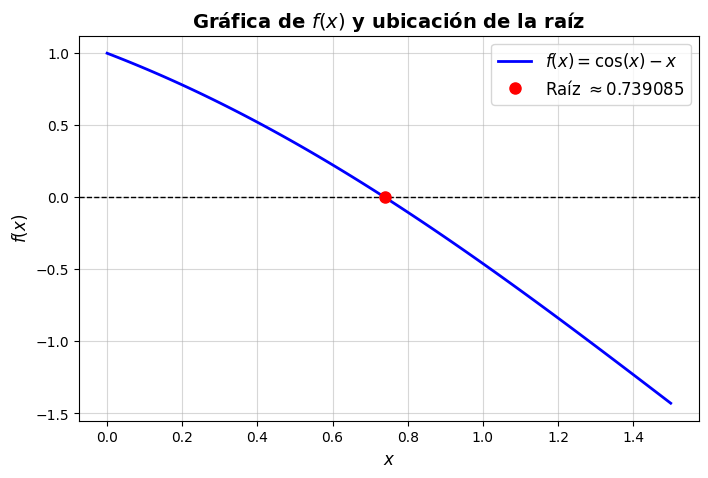

In [8]:
# Creamos un arreglo de valores x alrededor de la raíz
x_vals = np.linspace(0, 1.5, 100)
y_vals = f(x_vals)

# Configuración de la figura
plt.figure(figsize=(8, 5))
plt.plot(x_vals, y_vals, label=r'$f(x) = \cos(x) - x$', color='blue', linewidth=2)

# Resaltamos el eje x (y=0)
plt.axhline(0, color='black', linewidth=1, linestyle='--')

# Resaltamos la solución encontrada si el método fue exitoso
if solucion_final is not None:
    plt.plot(solucion_final, f(solucion_final), 'ro', markersize=8, label=f'Raíz $\\approx {solucion_final:.6f}$')

# Formato estético de la gráfica
plt.title('Gráfica de $f(x)$ y ubicación de la raíz', fontsize=14, fontweight='bold')
plt.xlabel('$x$', fontsize=12)
plt.ylabel('$f(x)$', fontsize=12)
plt.grid(True, alpha=0.5)
plt.legend(fontsize=12)

# Mostrar la gráfica
plt.show()